Step 0: Check Raman shift axis
  Raman shift points: 2048
  After dropping first 90 points, first x = 307.5439344
Step 1: Load dark spectrum
  Dark points loaded: 2048
  Using first 2048 dark points for subtraction
Step 2: Parse Raman log
  Parsed spectra: 112
  Failed blocks:   40
Step 3: raw-dark on 2048 points -> drop first 30 -> fast baseline correction
    processed 20/112 spectra
    processed 40/112 spectra
    processed 60/112 spectra
    processed 80/112 spectra
    processed 100/112 spectra
  Valid spectra after raw-dark, drop first 90, baseline correction: 112
  Skipped spectra (shorter than 2048): 0
  Stack shape (before normalization): (112, 1958)
  Raman shift start after drop: 307.5439344
  Raman shift end: 3234.5903580
Step 3.5: Single-spectrum diagnostic


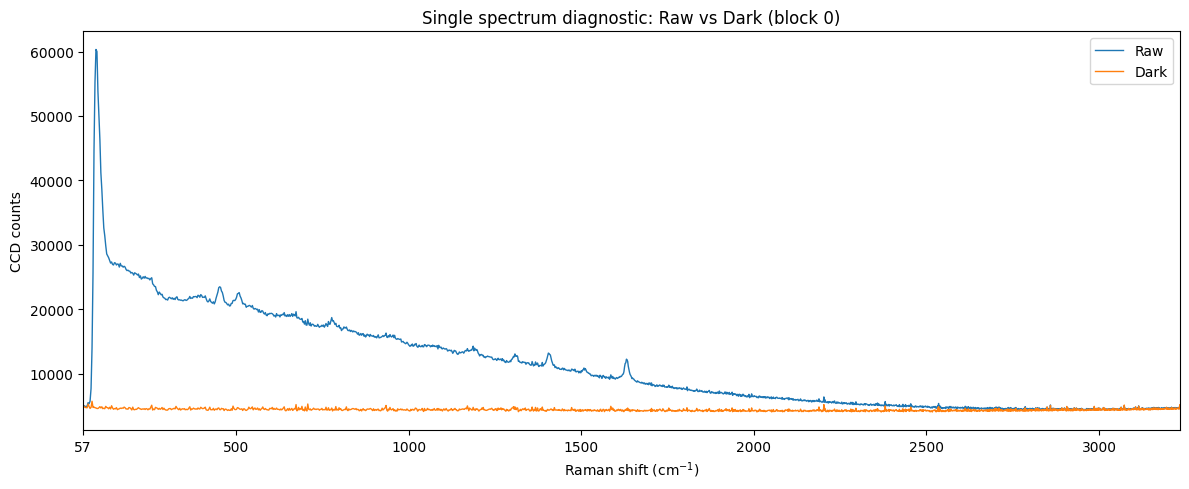

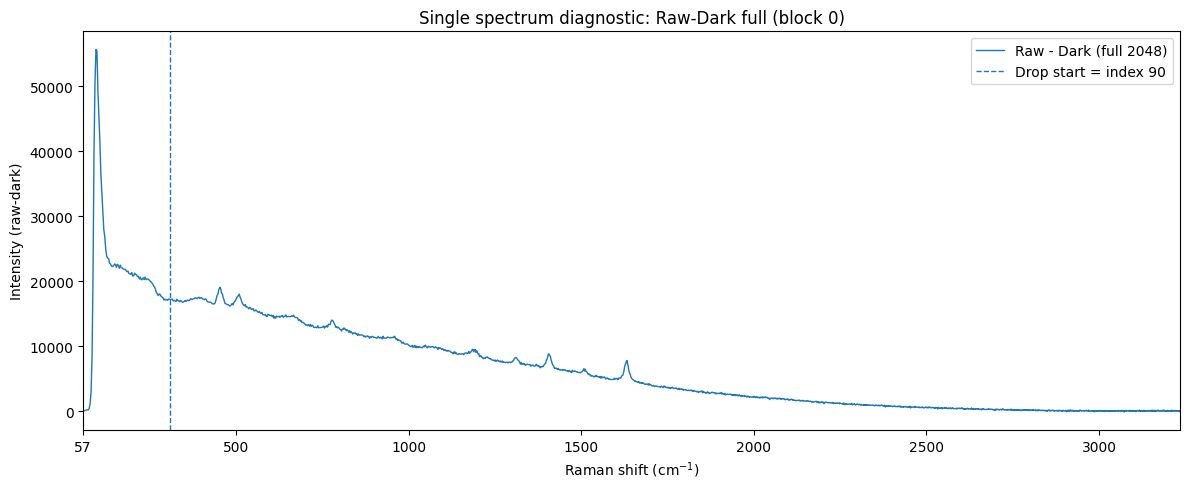

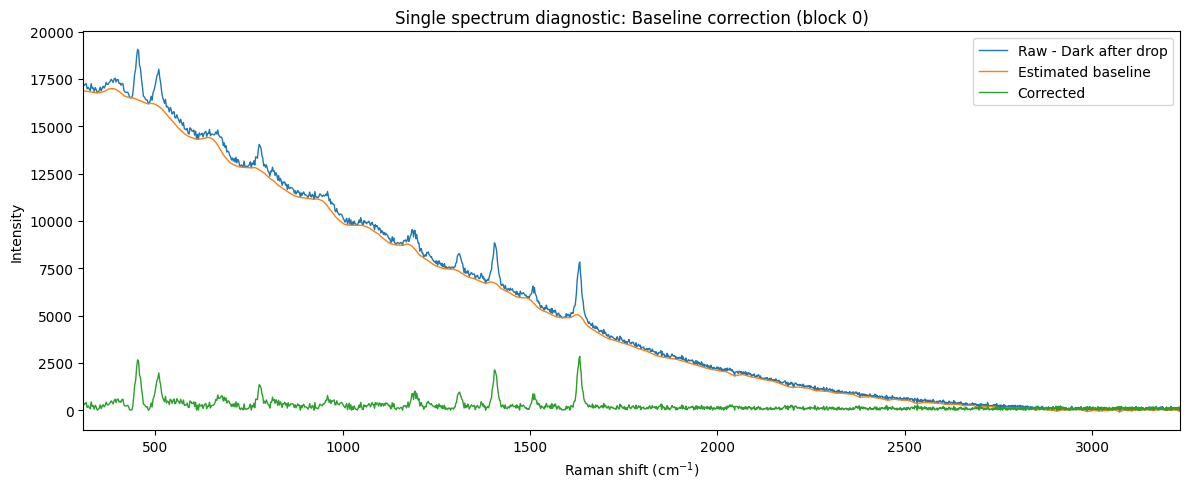

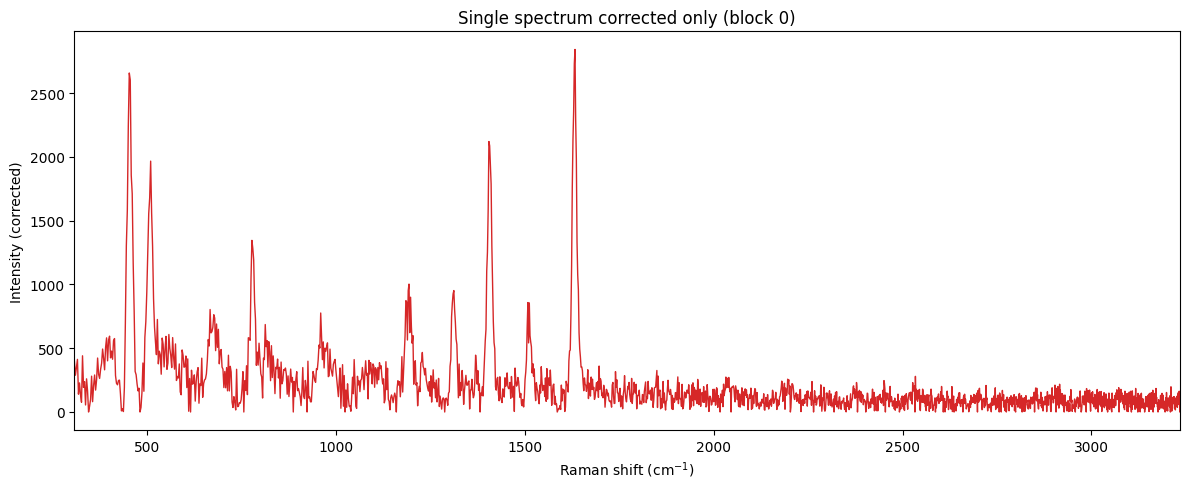

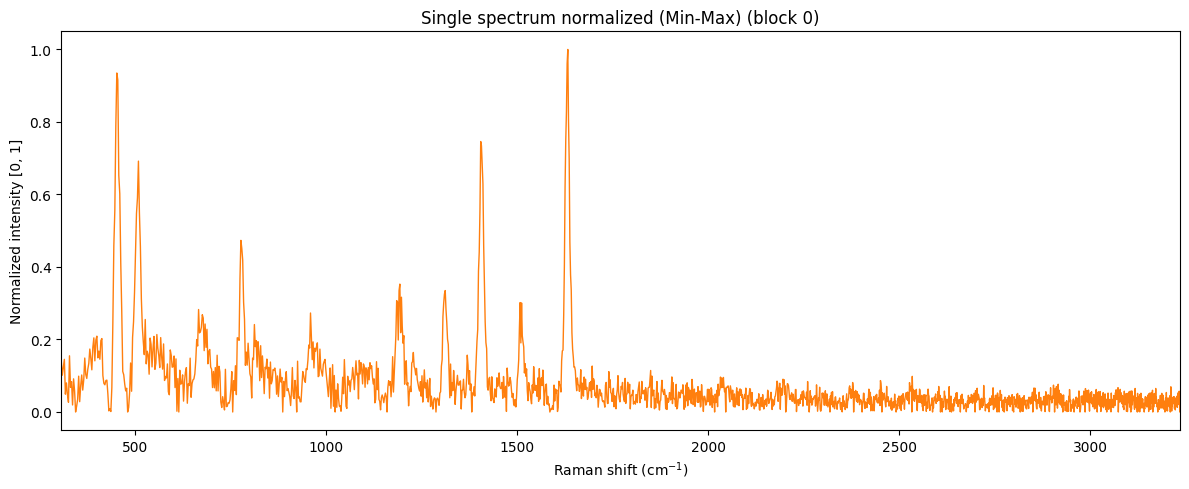

Step 3.6: Normalization (method=min_max)
  Baseline-raw stack shape: (112, 1958)
  Baseline-raw value range: [-0.000000, 3356.066650]
  Min-max stack shape: (112, 1958)
  Min-max value range: [0.000000, 1.000000]


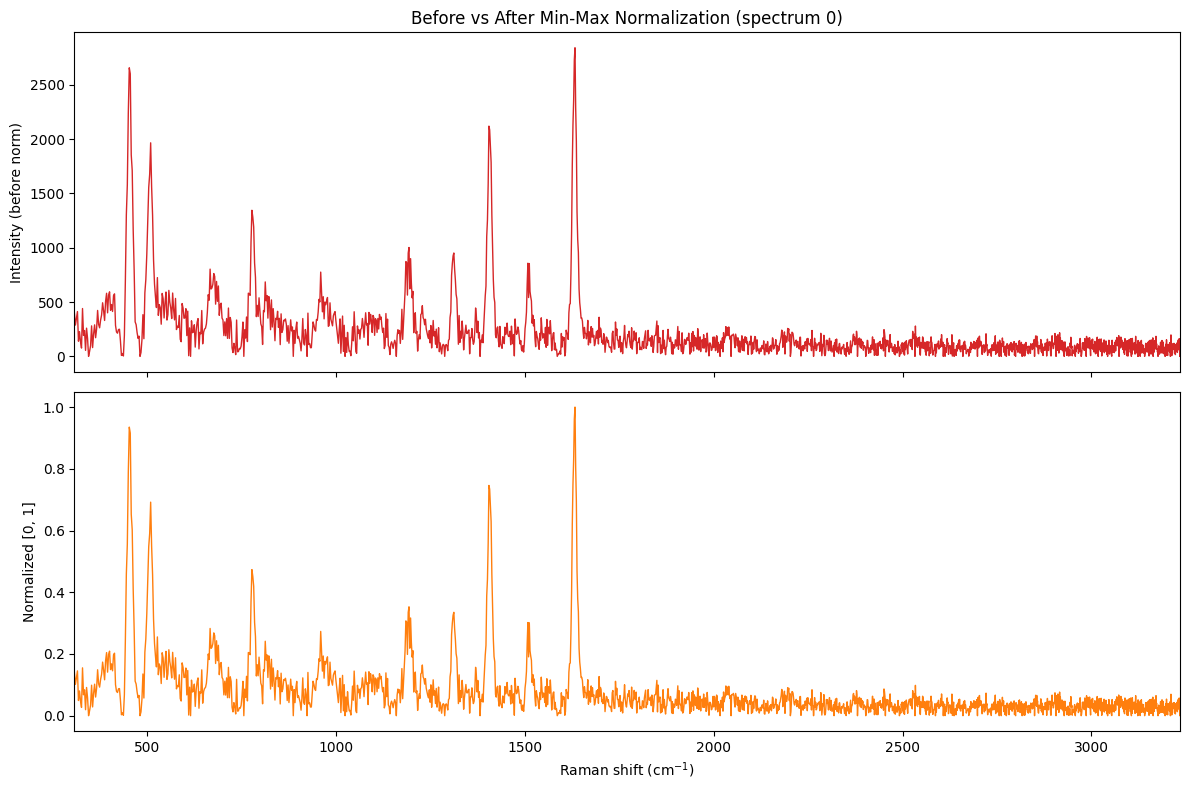

Step 4: Compute position-wise statistics
  Spectra used:     112
  Positions used:   1958
  Mean of means:    0.0737
  Mean of medians:  0.0711
  Mean of STDs:     0.0284
  Mean of SEMs:     0.0027
  Overall min:      0.0000
  Overall max:      1.0000
Step 4.5: Export training-ready data files
  Export directory: C:\Users\Jeremy666\OneDrive\Documents\laser_test\build\Desktop_Qt_6_6_3_MSVC2019_64bit-Debug\Training_data
  Saved default training spectra NPY: C:\Users\Jeremy666\OneDrive\Documents\laser_test\build\Desktop_Qt_6_6_3_MSVC2019_64bit-Debug\Training_data\training_spectra_adenine.npy
    shape = (112, 1958)  (n_spectra x n_positions)
    Each row = one fully processed spectrum = one training sample
  Saved baseline raw NPY: C:\Users\Jeremy666\OneDrive\Documents\laser_test\build\Desktop_Qt_6_6_3_MSVC2019_64bit-Debug\Training_data\training_spectra_adenine_baseline_raw.npy
    shape = (112, 1958)
  Saved min-max NPY: C:\Users\Jeremy666\OneDrive\Documents\laser_test\build\Desktop_Qt_6

,position_index,raman_shift_cm-1,n_valid,global_min,global_max,global_mean,global_median,global_std,global_variance,global_sem
0,0,307.543934,112,5.513389e-15,0.262023,0.122224,0.122449,0.051932,0.002697,0.004907
1,1,310.235545,112,0.000000e+00,0.343629,0.133914,0.131984,0.064439,0.004152,0.006089
2,2,312.925280,112,1.432827e-02,0.332353,0.154825,0.151031,0.059625,0.003555,0.005634
3,3,315.613142,112,3.549356e-02,0.342525,0.160050,0.160574,0.060158,0.003619,0.005684
4,4,318.299132,112,0.000000e+00,0.233784,0.087505,0.081628,0.052244,0.002729,0.004937
5,5,320.983253,112,1.339659e-15,0.242390,0.117656,0.109718,0.054779,0.003001,0.005176
6,6,323.665504,112,8.568014e-16,0.259902,0.093062,0.087643,0.051148,0.002616,0.004833
7,7,326.345889,112,0.000000e+00,0.203362,0.059361,0.049173,0.049165,0.002417,0.004646
8,8,329.024408,112,1.087334e-15,0.239312,0.092130,0.091350,0.055129,0.003039,0.005209
9,9,331.701063,112,0.000000e+00,0.278315,0.101201,0.103563,0.058300,0.003399,0.005509



Overall summary:


,log_file,dark_file,target_len,drop_first_n,baseline_correction,baseline_method,baseline_window,baseline_smooth,sample_name,normalization,...,n_spectra_used,n_positions_used,x_start_cm-1,x_end_cm-1,mean_of_global_mean,mean_of_global_median,mean_of_global_std,mean_of_global_sem,overall_min,overall_max
0,C:\Users\Jeremy666\OneDrive\Documents\laser_te...,C:\Users\Jeremy666\OneDrive\Documents\laser_te...,2048,90,True,rolling_minimum_plus_smoothing,15,15,adenine,True,...,112,1958,307.543934,3234.590358,0.073668,0.071057,0.028357,0.002679,0.0,1.0


Step 5: Plotting


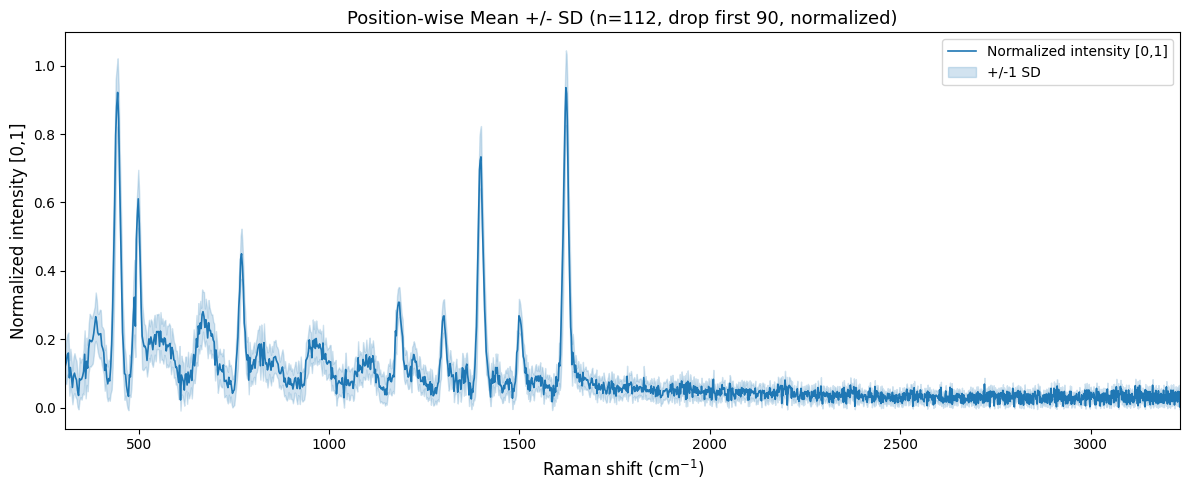

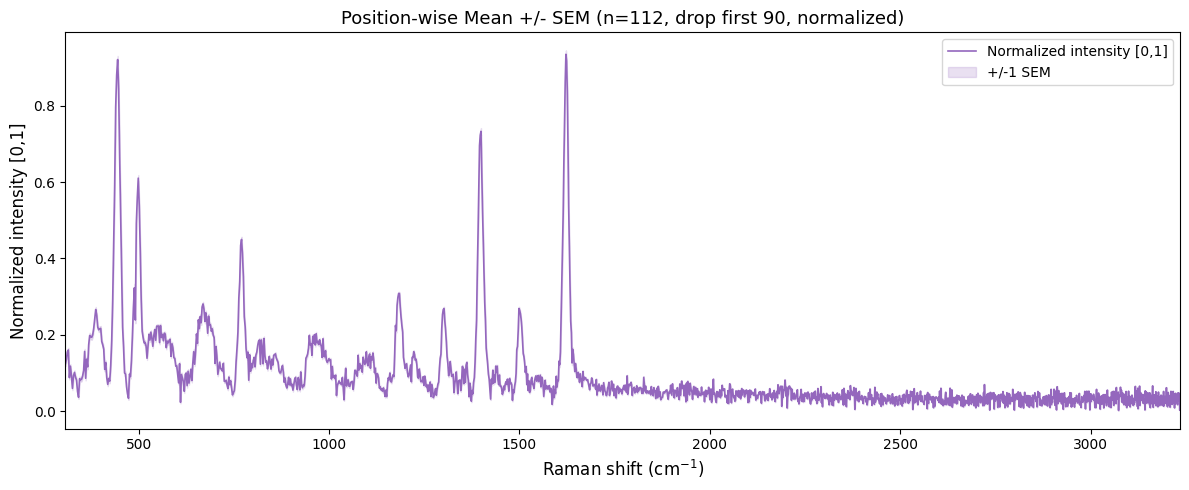

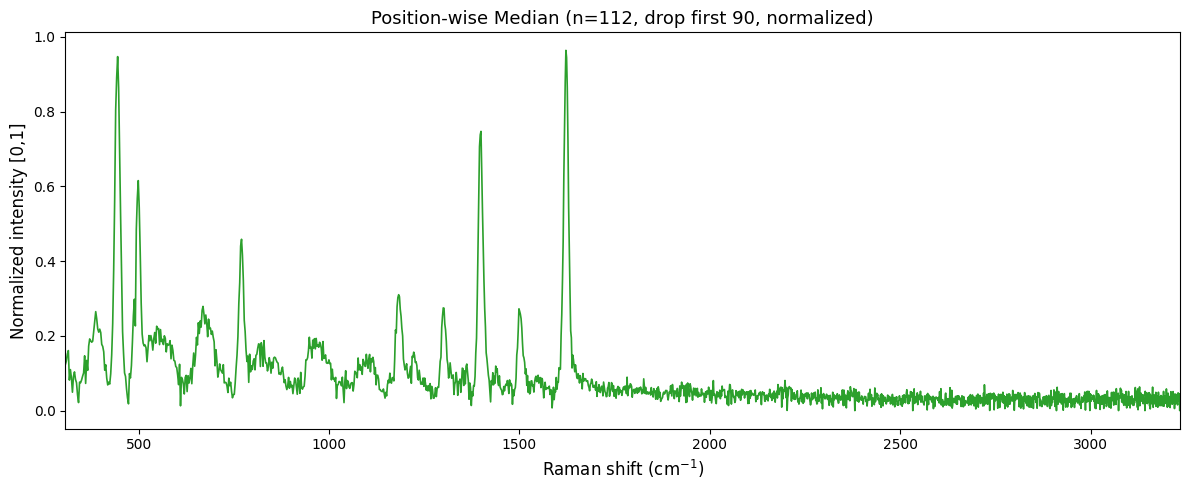

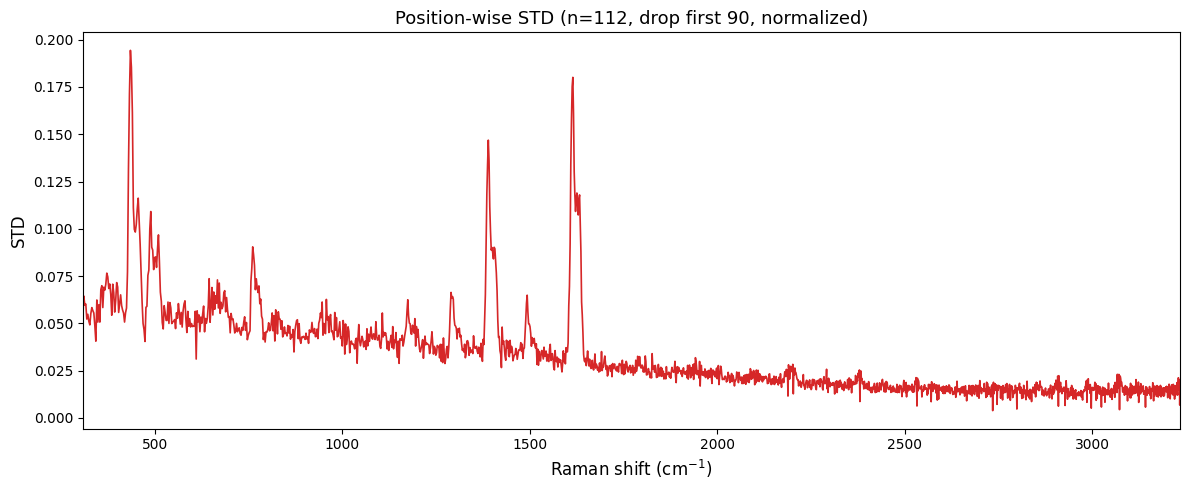

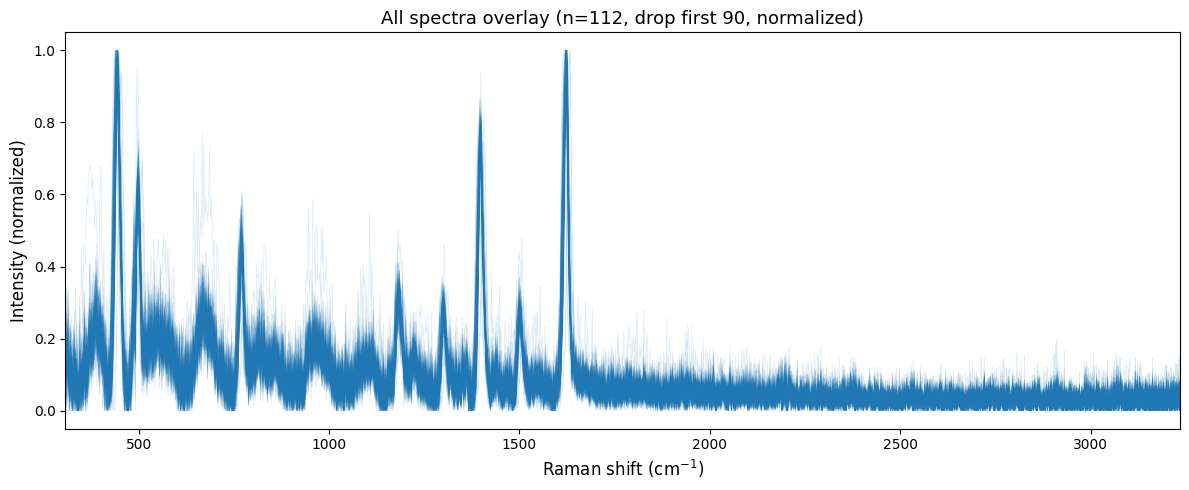

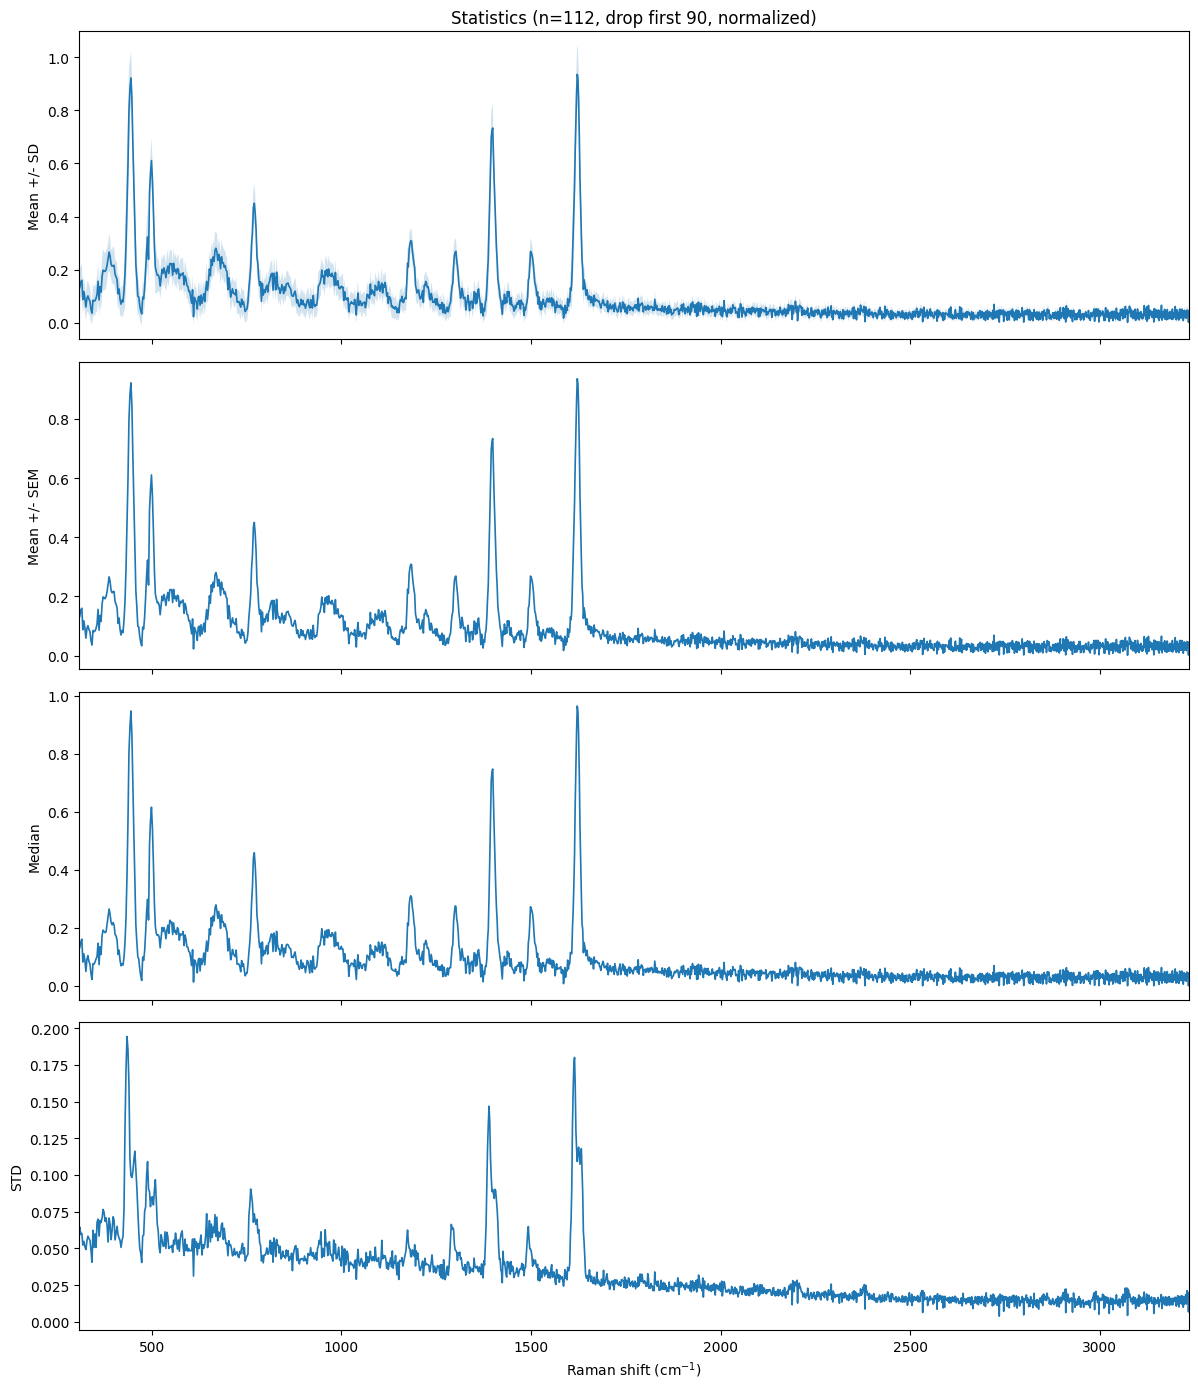

Done!

Final processing pipeline:
  1. Raw - Dark (2048 points)
  2. Drop first 90 points
  3. Baseline correction (window=15, smooth=15)
  4. Normalization (min_max) -> each spectrum scaled to [0, 1]
  5. Save both baseline_raw and min-max versions
  6. Statistics (mean, median, std, sem)

  Output stack shape: (112, 1958)
  All data exported to: C:\Users\Jeremy666\OneDrive\Documents\laser_test\build\Desktop_Qt_6_6_3_MSVC2019_64bit-Debug\Training_data
  Ready for CNN / Transformer / PCA-SVM with unified normalization.


In [3]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print


# =========================================================
# CONFIG
# =========================================================
LOG_FILE = r"/Users/adhar/Downloads/research/Portable_Raman_full_project/laser_test/build/Desktop_Qt_6_6_3_MSVC2019_64bit-Debug/portable_raman_test_data/laser_log_20260513_150549.txt"
DARK_PATH = r"/Users/adhar/Downloads/research/Portable_Raman_full_project/laser_test/build/Desktop_Qt_6_6_3_MSVC2019_64bit-Debug/portable_raman_test_data/dark_20260513_150739.txt"

# Training data export directory
TRAINING_DATA_DIR = Path(r"/Users/adhar/Downloads/research/Portable_Raman_full_project/laser_test/build/Desktop_Qt_6_6_3_MSVC2019_64bit-Debug/Training_data")
TRAINING_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Output file name prefix. Change this each time you process a different sample.
# For example: "r6g", "methylene_blue", "adenine", "di_water"
SAMPLE_NAME = "adenine"

TARGET_LEN = 2048
DROP_N = 90
REQUIRE_FULL_2048 = True
MAX_POINTS_TO_USE = None
SAVE_STACK_CSV = True

# =========================================================
# FAST BASELINE CORRECTION CONFIG
# You currently find 15 / 15 works best, so keep it for now
# =========================================================
DO_BASELINE_CORRECTION = True
BASELINE_WINDOW = 15
BASELINE_SMOOTH = 15

# =========================================================
# NORMALIZATION CONFIG
# Min-Max normalization: each spectrum is scaled independently to [0, 1]
# Use the same normalization throughout, to make later CNN / Transformer / PCA-SVM comparisons easier
# =========================================================
DO_NORMALIZATION = True
NORMALIZATION_METHOD = "min_max"  # Only min_max is used for now; can be extended later

# =========================================================
# SINGLE-SPECTRUM DIAGNOSTIC
# Used for comparison against a single spectrum from the large instrument
# None means automatically take the first valid spectrum
# You can also manually enter a block index, e.g. 0, 1, 5, 10
# =========================================================
DIAGNOSTIC_SPECTRUM_INDEX = None
SAVE_DIAGNOSTIC_CSV = True


# =========================================================
# 2048-point Raman shift axis
# Paste your own 2048 points here
# =========================================================
RAMAN_SHIFT_2048 = np.array([
    57.42448267, 60.29131328, 63.15612404, 66.01891664, 68.87969276, 71.73845411, 74.59520236, 77.44993921, 80.30266633, 83.15338541,
    86.00209813, 88.84880617, 91.6935112, 94.53621489, 97.37691893, 100.215625, 103.0523347, 105.8870498, 108.7197719, 111.5505026,
    114.3792437, 117.2059968, 120.0307636, 122.8535457, 125.6743447, 128.4931623, 131.3100002, 134.1248601, 136.9377435, 139.7486521,
    142.5575875, 145.3645515, 148.1695455, 150.9725714, 153.7736306, 156.5727249, 159.3698559, 162.1650252, 164.9582344, 167.7494851,
    170.5387791, 173.3261178, 176.111503, 178.8949363, 181.6764192, 184.4559533, 187.2335404, 190.009182, 192.7828797, 195.5546352,
    198.32445, 201.0923257, 203.8582639, 206.6222664, 209.3843345, 212.1444701, 214.9026745, 217.6589495, 220.4132966, 223.1657175,
    225.9162137, 228.6647868, 231.4114383, 234.15617, 236.8989832, 239.6398798, 242.3788611, 245.1159289, 247.8510846, 250.5843298,
    253.3156662, 256.0450953, 258.7726186, 261.4982377, 264.2219542, 266.9437697, 269.6636857, 272.3817038, 275.0978255, 277.8120524,
    280.524386, 283.234828, 285.9433797, 288.6500429, 291.3548191, 294.0577097, 296.7587164, 299.4578407, 302.1550841, 304.8504482,
    307.5439344, 310.2355445, 312.9252798, 315.6131419, 318.2991323, 320.9832527, 323.6655044, 326.3458891, 329.0244082, 331.7010633,
    334.3758559, 337.0487875, 339.7198596, 342.3890738, 345.0564316, 347.7219345, 350.3855839, 353.0473815, 355.7073287, 358.365427,
    361.0216779, 363.676083, 366.3286437, 368.9793615, 371.6282379, 374.2752745, 376.9204727, 379.5638341, 382.20536, 384.8450521,
    387.4829117, 390.1189404, 392.7531397, 395.385511, 398.0160559, 400.6447758, 403.2716721, 405.8967465, 408.5200003, 411.141435,
    413.7610521, 416.3788531, 418.9948394, 421.6090125, 424.2213739, 426.831925, 429.4406673, 432.0476023, 434.6527314,
    437.2560561, 439.8575778, 442.4572981, 445.0552182, 447.6513398, 450.2456643, 452.838193, 455.4289275, 458.0178692, 460.6050195,
    463.1903799, 465.7739518, 468.3557368, 470.9357361, 473.5139512, 476.0903837, 478.6650348, 481.2379061, 483.808999, 486.3783149,
    488.9458552, 491.5116214, 494.0756149, 496.637837, 499.1982893, 501.7569732, 504.31389, 506.8690412, 509.4224283, 511.9740525,
    514.5239154, 517.0720183, 519.6183627, 522.1629499, 524.7057814, 527.2468585, 529.7861828, 532.3237555, 534.8595781, 537.3936519,
    539.9259785, 542.4565591, 544.9853952, 547.5124881, 550.0378393, 552.5614502, 555.0833221, 557.6034563, 560.1218544, 562.6385177,
    565.1534476, 567.6666454, 570.1781125, 572.6878504, 575.1958603, 577.7021437, 580.206702, 582.7095365, 585.2106485, 587.7100395,
    590.2077108, 592.7036638, 595.1978999, 597.6904204, 600.1812266, 602.67032, 605.1577019, 607.6433737, 610.1273367, 612.6095922,
    615.0901417, 617.5689865, 620.0461278, 622.5215672, 624.9953059, 627.4673453, 629.9376867, 632.4063314, 634.8732809, 637.3385364,
    639.8020993, 642.2639709, 644.7241525, 647.1826456, 649.6394514, 652.0945713, 654.5480066, 656.9997586, 659.4498286, 661.8982181,
    664.3449282, 666.7899604, 669.2333159, 671.6749961, 674.1150023, 676.5533358, 678.9899979, 681.42499, 683.8583134, 686.2899693,
    688.7199592, 691.1482842, 693.5749457, 695.999945, 698.4232835, 700.8449624, 703.264983, 705.6833467, 708.1000547, 710.5151083,
    712.9285088, 715.3402576, 717.7503559, 720.158805, 722.5656063, 724.9707609, 727.3742702, 729.7761355, 732.1763581, 734.5749392,
    736.9718802, 739.3671822, 741.7608467, 744.1528749, 746.543268, 748.9320274, 751.3191543, 753.70465, 756.0885158, 758.4707529,
    760.8513626, 763.2303462, 765.6077049, 767.98344, 770.3575529, 772.7300447, 775.1009167, 777.4701702, 779.8378064, 782.2038266,
    784.568232, 786.931024, 789.2922037, 791.6517725, 794.0097315, 796.366082, 798.7208253, 801.0739627, 803.4254953, 805.7754244,
    808.1237513, 810.4704772, 812.8156033, 815.159131, 817.5010613, 819.8413957, 822.1801352, 824.5172812, 826.8528349, 829.1867974,
    831.5191702, 833.8499542, 836.1791509, 838.5067615, 840.832787, 843.1572289, 845.4800883, 847.8013664, 850.1210645, 852.4391837,
    854.7557254, 857.0706907, 859.3840808, 861.6958969, 864.0061403, 866.3148122, 868.6219138, 870.9274462, 873.2314108, 875.5338087,
    877.8346411, 880.1339093, 882.4316144, 884.7277576, 887.0223402, 889.3153633, 891.6068282, 893.896736, 896.1850879, 898.4718852,
    900.757129, 903.0408205, 905.3229609, 907.6035515, 909.8825933, 912.1600876, 914.4360356, 916.7104385, 918.9832974, 921.2546135,
    923.524388, 925.7926222, 928.059317, 930.3244739, 932.5880939, 934.8501782, 937.1107279, 939.3697443, 941.6272286, 943.8831818,
    946.1376052, 948.3905, 950.6418672, 952.8917082, 955.1400239, 957.3868157, 959.6320847, 961.875832, 964.1180587, 966.3587662,
    968.5979554, 970.8356276, 973.0717839, 975.3064255, 977.5395536, 979.7711692, 982.0012736, 984.2298678, 986.4569531, 988.6825306,
    990.9066014, 993.1291667, 995.3502276, 997.5697853, 999.7878409, 1002.004396, 1004.21945, 1006.433007, 1008.645065, 1010.855627,
    1013.064694, 1015.272267, 1017.478347, 1019.682935, 1021.886032, 1024.08764, 1026.287759, 1028.486391, 1030.683537, 1032.879197,
    1035.073374, 1037.266068, 1039.45728, 1041.647011, 1043.835263, 1046.022036, 1048.207333, 1050.391153, 1052.573498, 1054.754369,
    1056.933768, 1059.111694, 1061.288151, 1063.463137, 1065.636656, 1067.808707, 1069.979292, 1072.148412, 1074.316068, 1076.482261,
    1078.646992, 1080.810263, 1082.972075, 1085.132427, 1087.291323, 1089.448762, 1091.604746, 1093.759277, 1095.912354, 1098.063979,
    1100.214154, 1102.362878, 1104.510155, 1106.655983, 1108.800366, 1110.943303, 1113.084796, 1115.224845, 1117.363453, 1119.500619,
    1121.636346, 1123.770633, 1125.903483, 1128.034896, 1130.164874, 1132.293417, 1134.420527, 1136.546204, 1138.67045, 1140.793265,
    1142.914652, 1145.03461, 1147.153141, 1149.270246, 1151.385927, 1153.500183, 1155.613017, 1157.724429, 1159.83442, 1161.942992,
    1164.050145, 1166.15588, 1168.260199, 1170.363103, 1172.464592, 1174.564668, 1176.663332, 1178.760585, 1180.856427, 1182.950861,
    1185.043886, 1187.135505, 1189.225717, 1191.314525, 1193.401928, 1195.487929, 1197.572528, 1199.655727, 1201.737526, 1203.817926,
    1205.896928, 1207.974534, 1210.050744, 1212.12556, 1214.198982, 1216.271012, 1218.341651, 1220.410899, 1222.478758, 1224.545228,
    1226.610311, 1228.674008, 1230.736319, 1232.797247, 1234.856791, 1236.914953, 1238.971734, 1241.027134, 1243.081156, 1245.1338,
    1247.185066, 1249.234956, 1251.283471, 1253.330613, 1255.376381, 1257.420777, 1259.463802, 1261.505458, 1263.545744, 1265.584662,
    1267.622213, 1269.658399, 1271.693219, 1273.726675, 1275.758769, 1277.7895, 1279.818871, 1281.846881, 1283.873533, 1285.898827,
    1287.922764, 1289.945344, 1291.96657, 1293.986442, 1296.004961, 1298.022128, 1300.037944, 1302.05241, 1304.065527, 1306.077296,
    1308.087718, 1310.096794, 1312.104524, 1314.110911, 1316.115955, 1318.119656, 1320.122017, 1322.123037, 1324.122718, 1326.121061,
    1328.118067, 1330.113736, 1332.10807, 1334.10107, 1336.092737, 1338.083071, 1340.072074, 1342.059746, 1344.046089, 1346.031104,
    1348.014791, 1349.997152, 1351.978187, 1353.957897, 1355.936284, 1357.913348, 1359.889091, 1361.863513, 1363.836615, 1365.808398,
    1367.778863, 1369.748012, 1371.715844, 1373.682362, 1375.647565, 1377.611456, 1379.574034, 1381.535301, 1383.495258, 1385.453906,
    1387.411245, 1389.367277, 1391.322003, 1393.275423, 1395.227538, 1397.17835, 1399.12786, 1401.076067, 1403.022974, 1404.968581,
    1406.912889, 1408.8559, 1410.797613, 1412.73803, 1414.677153, 1416.61498, 1418.551515, 1420.486758, 1422.420709, 1424.353369,
    1426.28474, 1428.214823, 1430.143618, 1432.071126, 1433.997348, 1435.922286, 1437.845939, 1439.76831, 1441.689398, 1443.609205,
    1445.527732, 1447.44498, 1449.360949, 1451.275641, 1453.189056, 1455.101196, 1457.012061, 1458.921652, 1460.82997, 1462.737016,
    1464.642791, 1466.547296, 1468.450531, 1470.352499, 1472.253199, 1474.152632, 1476.0508, 1477.947703, 1479.843342, 1481.737719,
    1483.630833, 1485.522686, 1487.413279, 1489.302613, 1491.190689, 1493.077507, 1494.963068, 1496.847374, 1498.730425, 1500.612222,
    1502.492767, 1504.372059, 1506.250099, 1508.12689, 1510.002431, 1511.876724, 1513.749769, 1515.621567, 1517.49212, 1519.361427,
    1521.229491, 1523.096311, 1524.961889, 1526.826226, 1528.689322, 1530.551178, 1532.411796, 1534.271176, 1536.129319, 1537.986225,
    1539.841897, 1541.696334, 1543.549538, 1545.401509, 1547.252248, 1549.101756, 1550.950035, 1552.797084, 1554.642905, 1556.487499,
    1558.330867, 1560.173008, 1562.013925, 1563.853618, 1565.692088, 1567.529336, 1569.365363, 1571.200169, 1573.033756, 1574.866124,
    1576.697274, 1578.527207, 1580.355925, 1582.183427, 1584.009714, 1585.834788, 1587.658649, 1589.481299, 1591.302738, 1593.122966,
    1594.941985, 1596.759796, 1598.5764, 1600.391796, 1602.205987, 1604.018973, 1605.830755, 1607.641333, 1609.450709, 1611.258884,
    1613.065858, 1614.871632, 1616.676206, 1618.479583, 1620.281762, 1622.082745, 1623.882532, 1625.681124, 1627.478523, 1629.274728,
    1631.06974, 1632.863562, 1634.656192, 1636.447633, 1638.237885, 1640.026949, 1641.814826, 1643.601516, 1645.38702, 1647.17134,
    1648.954475, 1650.736428, 1652.517198, 1654.296787, 1656.075195, 1657.852423, 1659.628472, 1661.403343, 1663.177037, 1664.949554,
    1666.720896, 1668.491062, 1670.260055, 1672.027874, 1673.794521, 1675.559997, 1677.324301, 1679.087436, 1680.849401, 1682.610198,
    1684.369828, 1686.128291, 1687.885588, 1689.64172, 1691.396687, 1693.150492, 1694.903133, 1696.654613, 1698.404932, 1700.15409,
    1701.902089, 1703.64893, 1705.394613, 1707.139139, 1708.882508, 1710.624722, 1712.365782, 1714.105688, 1715.844441, 1717.582042,
    1719.318491, 1721.05379, 1722.787939, 1724.520939, 1726.252791, 1727.983496, 1729.713054, 1731.441466, 1733.168733, 1734.894856,
    1736.619836, 1738.343673, 1740.066368, 1741.787923, 1743.508337, 1745.227611, 1746.945747, 1748.662745, 1750.378606, 1752.093331,
    1753.80692, 1755.519374, 1757.230695, 1758.940882, 1760.649937, 1762.35786, 1764.064653, 1765.770315, 1767.474849, 1769.178253,
    1770.880531, 1772.581681, 1774.281705, 1775.980603, 1777.678378, 1779.375028, 1781.070555, 1782.76496, 1784.458244, 1786.150406,
    1787.841449, 1789.531373, 1791.220178, 1792.907866, 1794.594437, 1796.279891, 1797.964231, 1799.647455, 1801.329566, 1803.010564,
    1804.69045, 1806.369224, 1808.046887, 1809.723441, 1811.398885, 1813.073221, 1814.746449, 1816.41857, 1818.089585, 1819.759494,
    1821.428299, 1823.096, 1824.762598, 1826.428093, 1828.092487, 1829.75578, 1831.417972, 1833.079065, 1834.73906, 1836.397957,
    1838.055757, 1839.71246, 1841.368067, 1843.02258, 1844.675999, 1846.328324, 1847.979556, 1849.629697, 1851.278747, 1852.926706,
    1854.573575, 1856.219356, 1857.864048, 1859.507653, 1861.150171, 1862.791603, 1864.43195, 1866.071213, 1867.709391, 1869.346487,
    1870.982501, 1872.617433, 1874.251284, 1875.884055, 1877.515747, 1879.14636, 1880.775895, 1882.404353, 1884.031735, 1885.658041,
    1887.283273, 1888.90743, 1890.530513, 1892.152524, 1893.773463, 1895.39333, 1897.012127, 1898.629854, 1900.246512, 1901.862101,
    1903.476623, 1905.090078, 1906.702467, 1908.31379, 1909.924048, 1911.533243, 1913.141374, 1914.748442, 1916.354448, 1917.959394,
    1919.563278, 1921.166104, 1922.767869, 1924.368577, 1925.968227, 1927.56682, 1929.164357, 1930.760839, 1932.356266, 1933.950638,
    1935.543958, 1937.136224, 1938.727439, 1940.317603, 1941.906716, 1943.494779, 1945.081794, 1946.667759, 1948.252678, 1949.836549,
    1951.419374, 1953.001153, 1954.581888, 1956.161578, 1957.740225, 1959.317829, 1960.894391, 1962.469912, 1964.044392, 1965.617832,
    1967.190233, 1968.761596, 1970.33192, 1971.901207, 1973.469458, 1975.036673, 1976.602853, 1978.167999, 1979.732111, 1981.29519,
    1982.857236, 1984.418251, 1985.978235, 1987.537189, 1989.095113, 1990.652009, 1992.207876, 1993.762716, 1995.316528, 1996.869315,
    1998.421077, 1999.971813, 2001.521526, 2003.070215, 2004.617882, 2006.164526, 2007.710149, 2009.254752, 2010.798334, 2012.340898,
    2013.882442, 2015.422969, 2016.962479, 2018.500972, 2020.038449, 2021.57491, 2023.110358, 2024.644791, 2026.178211, 2027.710619,
    2029.242015, 2030.7724, 2032.301774, 2033.830138, 2035.357493, 2036.88384, 2038.409179, 2039.933511, 2041.456836, 2042.979156,
    2044.50047, 2046.02078, 2047.540086, 2049.058389, 2050.575689, 2052.091988, 2053.607285, 2055.121582, 2056.63488, 2058.147178,
    2059.658477, 2061.168779, 2062.678083, 2064.186391, 2065.693703, 2067.20002, 2068.705343, 2070.209671, 2071.713007, 2073.215349,
    2074.7167, 2076.21706, 2077.716429, 2079.214808, 2080.712197, 2082.208599, 2083.704012, 2085.198437, 2086.691876, 2088.18433,
    2089.675797, 2091.16628, 2092.655779, 2094.144294, 2095.631827, 2097.118377, 2098.603946, 2100.088534, 2101.572142, 2103.054771,
    2104.53642, 2106.017091, 2107.496785, 2108.975501, 2110.453242, 2111.930006, 2113.405795, 2114.88061, 2116.354452, 2117.82732,
    2119.299215, 2120.770139, 2122.240092, 2123.709074, 2125.177086, 2126.644128, 2128.110202, 2129.575308, 2131.039447, 2132.502618,
    2133.964824, 2135.426064, 2136.886339, 2138.34565, 2139.803998, 2141.261382, 2142.717804, 2144.173264, 2145.627763, 2147.081302,
    2148.533881, 2149.985501, 2151.436162, 2152.885865, 2154.334611, 2155.7824, 2157.229233, 2158.67511, 2160.120033, 2161.564001,
    2163.007016, 2164.449078, 2165.890188, 2167.330346, 2168.769552, 2170.207809, 2171.645115, 2173.081472, 2174.51688, 2175.951341,
    2177.384854, 2178.81742, 2180.24904, 2181.679715, 2183.109445, 2184.53823, 2185.966071, 2187.39297, 2188.818926, 2190.24394,
    2191.668013, 2193.091145, 2194.513337, 2195.93459, 2197.354904, 2198.77428, 2200.192718, 2201.610219, 2203.026784, 2204.442413,
    2205.857107, 2207.270866, 2208.683691, 2210.095583, 2211.506543, 2212.91657, 2214.325665, 2215.73383, 2217.141064, 2218.547369,
    2219.952744, 2221.357191, 2222.76071, 2224.163301, 2225.564966, 2226.965705, 2228.365518, 2229.764406, 2231.16237, 2232.55941,
    2233.955527, 2235.350722, 2236.744994, 2238.138345, 2239.530775, 2240.922286, 2242.312876, 2243.702548, 2245.091301, 2246.479136,
    2247.866054, 2249.252056, 2250.637142, 2252.021312, 2253.404567, 2254.786908, 2256.168335, 2257.548849, 2258.928451, 2260.30714,
    2261.684919, 2263.061786, 2264.437744, 2265.812792, 2267.186931, 2268.560161, 2269.932484, 2271.303899, 2272.674408, 2274.04401,
    2275.412708, 2276.7805, 2278.147388, 2279.513372, 2280.878453, 2282.242631, 2283.605907, 2284.968282, 2286.329756, 2287.69033,
    2289.050004, 2290.408779, 2291.766655, 2293.123633, 2294.479714, 2295.834898, 2297.189186, 2298.542578, 2299.895075, 2301.246677,
    2302.597386, 2303.9472, 2305.296123, 2306.644152, 2307.991291, 2309.337538, 2310.682894, 2312.02736, 2313.370937, 2314.713626,
    2316.055425, 2317.396337, 2318.736362, 2320.075501, 2321.413753, 2322.75112, 2324.087602, 2325.423199, 2326.757913, 2328.091744,
    2329.424692, 2330.756757, 2332.087942, 2333.418245, 2334.747668, 2336.076211, 2337.403874, 2338.730659, 2340.056566, 2341.381595,
    2342.705747, 2344.029023, 2345.351423, 2346.672947, 2347.993596, 2349.313371, 2350.632273, 2351.950301, 2353.267456, 2354.58374,
    2355.899152, 2357.213693, 2358.527363, 2359.840164, 2361.152095, 2362.463158, 2363.773352, 2365.082679, 2366.391138, 2367.698731,
    2369.005458, 2370.31132, 2371.616316, 2372.920448, 2374.223717, 2375.526122, 2376.827664, 2378.128344, 2379.428163, 2380.72712,
    2382.025217, 2383.322453, 2384.61883, 2385.914349, 2387.209008, 2388.50281, 2389.795755, 2391.087843, 2392.379075, 2393.669451,
    2394.958971, 2396.247637, 2397.535449, 2398.822408, 2400.108513, 2401.393766, 2402.678167, 2403.961717, 2405.244416, 2406.526264,
    2407.807263, 2409.087412, 2410.366713, 2411.645165, 2412.92277, 2414.199527, 2415.475438, 2416.750503, 2418.024723, 2419.298097,
    2420.570627, 2421.842313, 2423.113155, 2424.383155, 2425.652312, 2426.920627, 2428.188101, 2429.454735, 2430.720528, 2431.985481,
    2433.249595, 2434.51287, 2435.775307, 2437.036907, 2438.297669, 2439.557595, 2440.816685, 2442.074939, 2443.332358, 2444.588943,
    2445.844694, 2447.099611, 2448.353695, 2449.606947, 2450.859367, 2452.110956, 2453.361714, 2454.611641, 2455.860739, 2457.109007,
    2458.356446, 2459.603058, 2460.848841, 2462.093797, 2463.337927, 2464.58123, 2465.823708, 2467.06536, 2468.306188, 2469.546191,
    2470.785371, 2472.023728, 2473.261262, 2474.497974, 2475.733864, 2476.968934, 2478.203183, 2479.436611, 2480.66922, 2481.901011,
    2483.131982, 2484.362136, 2485.591472, 2486.81999, 2488.047693, 2489.274579, 2490.50065, 2491.725906, 2492.950348, 2494.173975,
    2495.396789, 2496.61879, 2497.839979, 2499.060355, 2500.27992, 2501.498675, 2502.716618, 2503.933752, 2505.150076, 2506.365592,
    2507.580298, 2508.794197, 2510.007289, 2511.219573, 2512.431051, 2513.641723, 2514.85159, 2516.060652, 2517.268909, 2518.476362,
    2519.683012, 2520.888858, 2522.093902, 2523.298145, 2524.501585, 2525.704225, 2526.906064, 2528.107104, 2529.307343, 2530.506784,
    2531.705426, 2532.90327, 2534.100317, 2535.296566, 2536.492019, 2537.686676, 2538.880537, 2540.073603, 2541.265875, 2542.457352,
    2543.648036, 2544.837927, 2546.027025, 2547.21533, 2548.402845, 2549.589567, 2550.7755, 2551.960642, 2553.144994, 2554.328557,
    2555.511331, 2556.693317, 2557.874515, 2559.054926, 2560.23455, 2561.413387, 2562.591439, 2563.768705, 2564.945187, 2566.120884,
    2567.295797, 2568.469926, 2569.643273, 2570.815837, 2571.987619, 2573.158619, 2574.328839, 2575.498278, 2576.666936, 2577.834815,
    2579.001915, 2580.168236, 2581.333779, 2582.498545, 2583.662533, 2584.825744, 2585.988179, 2587.149838, 2588.310721, 2589.47083,
    2590.630165, 2591.788725, 2592.946512, 2594.103526, 2595.259767, 2596.415237, 2597.569934, 2598.723861, 2599.877017, 2601.029403,
    2602.181019, 2603.331866, 2604.481944, 2605.631254, 2606.779796, 2607.92757, 2609.074578, 2610.220819, 2611.366295, 2612.511004,
    2613.654949, 2614.798129, 2615.940545, 2617.082198, 2618.223087, 2619.363214, 2620.502578, 2621.64118, 2622.779022, 2623.916102,
    2625.052422, 2626.187982, 2627.322782, 2628.456824, 2629.590107, 2630.722631, 2631.854399, 2632.985409, 2634.115662, 2635.245159,
    2636.3739, 2637.501886, 2638.629117, 2639.755593, 2640.881316, 2642.006285, 2643.130501, 2644.253964, 2645.376676, 2646.498635,
    2647.619843, 2648.740301, 2649.860008, 2650.978965, 2652.097173, 2653.214632, 2654.331343, 2655.447305, 2656.56252, 2657.676987,
    2658.790708, 2659.903683, 2661.015911, 2662.127395, 2663.238133, 2664.348127, 2665.457377, 2666.565884, 2667.673647, 2668.780667,
    2669.886946, 2670.992483, 2672.097278, 2673.201332, 2674.304646, 2675.40722, 2676.509055, 2677.61015, 2678.710507, 2679.810125,
    2680.909006, 2682.007149, 2683.104556, 2684.201226, 2685.29716, 2686.392359, 2687.486822, 2688.580551, 2689.673545, 2690.765806,
    2691.857334, 2692.948128, 2694.03819, 2695.12752, 2696.216119, 2697.303986, 2698.391123, 2699.477529, 2700.563206, 2701.648153,
    2702.732371, 2703.81586, 2704.898622, 2705.980656, 2707.061963, 2708.142543, 2709.222396, 2710.301524, 2711.379926, 2712.457603,
    2713.534556, 2714.610784, 2715.686289, 2716.76107, 2717.835129, 2718.908465, 2719.981079, 2721.052972, 2722.124143, 2723.194594,
    2724.264324, 2725.333335, 2726.401626, 2727.469198, 2728.536051, 2729.602187, 2730.667605, 2731.732305, 2732.796289, 2733.859556,
    2734.922107, 2735.983943, 2737.045063, 2738.105469, 2739.16516, 2740.224138, 2741.282402, 2742.339953, 2743.396792, 2744.452918,
    2745.508333, 2746.563036, 2747.617029, 2748.670311, 2749.722883, 2750.774745, 2751.825899, 2752.876343, 2753.926079, 2754.975107,
    2756.023428, 2757.071041, 2758.117948, 2759.164149, 2760.209643, 2761.254433, 2762.298517, 2763.341897, 2764.384572, 2765.426544,
    2766.467813, 2767.508378, 2768.548241, 2769.587402, 2770.625862, 2771.66362, 2772.700677, 2773.737034, 2774.772691, 2775.807648,
    2776.841907, 2777.875466, 2778.908327, 2779.94049, 2780.971956, 2782.002725, 2783.032797, 2784.062172, 2785.090852, 2786.118836,
    2787.146125, 2788.17272, 2789.198621, 2790.223827, 2791.24834, 2792.272161, 2793.295288, 2794.317724, 2795.339467, 2796.36052,
    2797.380881, 2798.400552, 2799.419533, 2800.437824, 2801.455426, 2802.472339, 2803.488563, 2804.504099, 2805.518948, 2806.533109,
    2807.546584, 2808.559372, 2809.571474, 2810.58289, 2811.593621, 2812.603667, 2813.613029, 2814.621706, 2815.6297, 2816.637011,
    2817.643639, 2818.649584, 2819.654848, 2820.65943, 2821.66333, 2822.66655, 2823.669089, 2824.670948, 2825.672128, 2826.672628,
    2827.67245, 2828.671593, 2829.670058, 2830.667846, 2831.664956, 2832.661389, 2833.657146, 2834.652227, 2835.646632, 2836.640362,
    2837.633417, 2838.625798, 2839.617505, 2840.608537, 2841.598897, 2842.588584, 2843.577598, 2844.56594, 2845.553611, 2846.54061,
    2847.526938, 2848.512596, 2849.497583, 2850.481901, 2851.46555, 2852.448529, 2853.43084, 2854.412483, 2855.393458, 2856.373766,
    2857.353407, 2858.332381, 2859.310689, 2860.288331, 2861.265307, 2862.241619, 2863.217266, 2864.192248, 2865.166567, 2866.140222,
    2867.113215, 2868.085544, 2869.057211, 2870.028216, 2870.99856, 2871.968242, 2872.937264, 2873.905625, 2874.873326, 2875.840368,
    2876.80675, 2877.772474, 2878.737539, 2879.701945, 2880.665695, 2881.628786, 2882.591221, 2883.553, 2884.514122, 2885.474588,
    2886.434399, 2887.393555, 2888.352056, 2889.309903, 2890.267096, 2891.223636, 2892.179522, 2893.134756, 2894.089337, 2895.043266,
    2895.996544, 2896.949171, 2897.901146, 2898.852471, 2899.803146, 2900.753172, 2901.702548, 2902.651275, 2903.599353, 2904.546783,
    2905.493566, 2906.439701, 2907.385188, 2908.330029, 2909.274224, 2910.217773, 2911.160676, 2912.102934, 2913.044547, 2913.985516,
    2914.925841, 2915.865523, 2916.804562, 2917.742959, 2918.680714, 2919.617828, 2920.554302, 2921.490136, 2922.425331, 2923.359887,
    2924.293805, 2925.227086, 2926.15973, 2927.091738, 2928.023111, 2928.953849, 2929.883952, 2930.813422, 2931.742259, 2932.670464,
    2933.598037, 2934.524979, 2935.45129, 2936.37697, 2937.302021, 2938.226443, 2939.150236, 2940.073401, 2940.995939, 2941.917849,
    2942.839133, 2943.759792, 2944.679824, 2945.599232, 2946.518015, 2947.436174, 2948.353709, 2949.270621, 2950.18691, 2951.102577,
    2952.017622, 2952.932045, 2953.845848, 2954.759029, 2955.671591, 2956.583533, 2957.494855, 2958.405558, 2959.315643, 2960.22511,
    2961.133959, 2962.042191, 2962.949806, 2963.856805, 2964.763187, 2965.668954, 2966.574105, 2967.478641, 2968.382562, 2969.285868,
    2970.18856, 2971.090638, 2971.992103, 2972.892955, 2973.793193, 2974.683049, 2975.581676, 2976.479684, 2977.377073, 2978.273842,
    2979.169993, 2980.065526, 2980.960441, 2981.854738, 2982.748418, 2983.641481, 2984.533928, 2985.425759, 2986.316974, 2987.207573,
    2988.097558, 2988.986927, 2989.875683, 2990.763824, 2991.651352, 2992.538266, 2993.424568, 2994.310257, 2995.195334, 2996.079798,
    2996.963652, 2997.846894, 2998.729525, 2999.611546, 3000.492956, 3001.373757, 3002.253949, 3003.133531, 3004.012504, 3004.89087,
    3005.768627, 3006.645776, 3007.522318, 3008.398253, 3009.273582, 3010.148304, 3011.02242, 3011.89593, 3012.768835, 3013.641136,
    3014.512831, 3015.383923, 3016.25441, 3017.124294, 3017.993575, 3018.862253, 3019.730329, 3020.597802, 3021.464673, 3022.330943,
    3023.196612, 3024.06168, 3024.926148, 3025.790015, 3026.653283, 3027.515951, 3028.37802, 3029.23949, 3030.100362, 3030.960636,
    3031.820312, 3032.679391, 3033.537873, 3034.395758, 3035.253047, 3036.109739, 3036.965836, 3037.821338, 3038.676245, 3039.530557,
    3040.384274, 3041.237398, 3042.089928, 3042.941865, 3043.793208, 3044.643959, 3045.494118, 3046.343685, 3047.19266, 3048.041044,
    3048.888837, 3049.736039, 3050.582651, 3051.428673, 3052.274105, 3053.118948, 3053.963202, 3054.806868, 3055.649945, 3056.492435,
    3057.334336, 3058.175651, 3059.016378, 3059.856519, 3060.696074, 3061.535042, 3062.373425, 3063.211223, 3064.048436, 3064.885064,
    3065.721108, 3066.556568, 3067.391444, 3068.225737, 3069.059447, 3069.892575, 3070.72512, 3071.557083, 3072.388464, 3073.219264,
    3074.049484, 3074.879122, 3075.70818, 3076.536658, 3077.364557, 3078.191876, 3079.018616, 3079.844778, 3080.670361, 3081.495366,
    3082.319793, 3083.143643, 3083.966916, 3084.789612, 3085.611732, 3086.433276, 3087.254244, 3088.074636, 3088.894454, 3089.713697,
    3090.532365, 3091.350459, 3092.167979, 3092.984926, 3093.8013, 3094.617101, 3095.432329, 3096.246985, 3097.061069, 3097.874582,
    3098.687524, 3099.499894, 3100.311694, 3101.122924, 3101.933584, 3102.743675, 3103.553196, 3104.362148, 3105.170531, 3105.978346,
    3106.785593, 3107.592273, 3108.398385, 3109.20393, 3110.008908, 3110.81332, 3111.617166, 3112.420446, 3113.22316, 3114.02531,
    3114.826894, 3115.627915, 3116.428371, 3117.228263, 3118.027591, 3118.826357, 3119.624559, 3120.422199, 3121.219277, 3122.015792,
    3122.811747, 3123.60714, 3124.401972, 3125.196244, 3125.989955, 3126.783106, 3127.575697, 3128.367729, 3129.159202, 3129.950116,
    3130.740472, 3131.53027, 3132.319509, 3133.108191, 3133.896316, 3134.683884, 3135.470894, 3136.257348, 3137.043246, 3137.828587,
    3138.613373, 3139.397603, 3140.181279, 3140.964399, 3141.746965, 3142.528977, 3143.310435, 3144.091339, 3144.871689, 3145.651486,
    3146.430729, 3147.20942, 3147.987558, 3148.765143, 3149.542176, 3150.318657, 3151.094586, 3151.869963, 3152.644789, 3153.419064,
    3154.192787, 3154.96596, 3155.738582, 3156.510654, 3157.282175, 3158.053146, 3158.823568, 3159.593439, 3160.362761, 3161.131534,
    3161.899758, 3162.667433, 3163.434559, 3164.201137, 3164.967167, 3165.732649, 3166.497583, 3167.261969, 3168.025807, 3168.789098,
    3169.551842, 3170.314038, 3171.075688, 3171.83679, 3172.597346, 3173.357356, 3174.116818, 3174.875735, 3175.634105, 3176.391929,
    3177.149208, 3177.90594, 3178.662128, 3179.41777, 3180.172867, 3180.927419, 3181.681427, 3182.43489, 3183.187809, 3183.940183,
    3184.692014, 3185.443301, 3186.194044, 3186.944244, 3187.693901, 3188.443014, 3189.191585, 3189.939612, 3190.687096, 3191.434038,
    3192.180437, 3192.926294, 3193.671609, 3194.416381, 3195.160612, 3195.904301, 3196.647448, 3197.390054, 3198.132119, 3198.873642,
    3199.614624, 3200.355066, 3201.094966, 3201.834326, 3202.573146, 3203.311425, 3204.049164, 3204.786363, 3205.523022, 3206.259141,
    3206.994721, 3207.729761, 3208.464262, 3209.198223, 3209.931645, 3210.664528, 3211.396872, 3212.128677, 3212.859944, 3213.590672,
    3214.320862, 3215.050513, 3215.779626, 3216.508201, 3217.236238, 3217.963738, 3218.690699, 3219.417123, 3220.14301, 3220.868359,
    3221.593171, 3222.317446, 3223.141185, 3223.792853, 3224.516323, 3225.239273, 3225.961702, 3226.683611, 3227.405001, 3228.12587,
    3228.84622, 3229.566051, 3230.285363, 3231.004157, 3231.722432, 3232.44019, 3233.15743, 3233.874153, 3234.590358

], dtype=np.float64)


# =========================================================
# PARSING
# =========================================================
ERROR_PHRASE = "image data error code 0x0001"


def strip_prefix(line: str) -> str:
    line = line.strip()
    line = re.sub(r"^\[[^\]]+\]\s+\[Backend\]\s*", "", line)
    line = re.sub(r"^\[[^\]]+\]\s*", "", line)
    return line.strip()


def load_dark_spectrum(dark_path: str) -> np.ndarray:
    path = Path(dark_path)
    if not path.exists():
        raise FileNotFoundError(f"Dark file not found: {dark_path}")

    intensities = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#") or line.startswith("index"):
                continue
            parts = line.split("\t")
            if len(parts) >= 3:
                try:
                    intensities.append(float(parts[2]))
                except ValueError:
                    continue

    dark = np.asarray(intensities, dtype=np.float64)
    if dark.size == 0:
        raise ValueError(f"Dark file parsed but no intensity values found: {dark_path}")
    return dark


def parse_portable_log_to_spectra(log_file: str):
    lines = Path(log_file).read_text(encoding="utf-8", errors="ignore").splitlines()

    spectra = []
    failed = 0
    i = 0

    while i < len(lines):
        line_raw = lines[i]
        low = line_raw.lower()
        line = strip_prefix(line_raw)

        if ERROR_PHRASE in low:
            failed += 1
            i += 1
            continue

        if line.startswith("Image Data"):
            tokens = list(re.findall(r"\b[0-9A-Fa-f]{2,4}\b", line[len("Image Data"):].strip()))
            j = i + 1
            block_err = False

            while j < len(lines):
                nxt_raw = lines[j]
                nxt = strip_prefix(nxt_raw)

                if ERROR_PHRASE in nxt_raw.lower():
                    block_err = True

                if nxt.startswith("Stop Capture") or (nxt.startswith("Image Data") and j != i):
                    break

                hexes = re.findall(r"\b[0-9A-Fa-f]{2,4}\b", nxt)
                if hexes:
                    tokens.extend(hexes)
                j += 1

            if block_err or not tokens:
                failed += 1
            else:
                vals = np.array([int(t, 16) for t in tokens], dtype=np.int64)

                if vals.size % 2 == 0 and vals.max(initial=0) <= 255:
                    le = vals[0::2] + (vals[1::2] << 8)
                    be = (vals[0::2] << 8) + vals[1::2]
                    v16 = le if le.max(initial=0) >= be.max(initial=0) else be
                    if v16.max(initial=0) > 255:
                        vals = v16.astype(np.int64)

                spectra.append(vals.astype(np.float64))

            i = j + 1
            continue

        i += 1

    return spectra, failed


# =========================================================
# FAST BASELINE CORRECTION
# =========================================================
def moving_average(y: np.ndarray, window: int) -> np.ndarray:
    window = int(max(3, window))
    if window % 2 == 0:
        window += 1
    pad = window // 2
    ypad = np.pad(y, (pad, pad), mode="edge")
    kernel = np.ones(window, dtype=np.float64) / window
    out = np.convolve(ypad, kernel, mode="valid")
    return out


def rolling_minimum(y: np.ndarray, window: int) -> np.ndarray:
    window = int(max(3, window))
    if window % 2 == 0:
        window += 1
    pad = window // 2
    ypad = np.pad(y, (pad, pad), mode="edge")
    out = np.empty_like(y, dtype=np.float64)
    for i in range(y.size):
        out[i] = np.min(ypad[i:i + window])
    return out


def estimate_baseline_fast(y, window=151, smooth=81):
    y = np.asarray(y, dtype=np.float64)
    if y.size < 5:
        return np.zeros_like(y)
    baseline = rolling_minimum(y, window=window)
    baseline = moving_average(baseline, window=smooth)
    return baseline


def baseline_correction_fast(y, window=151, smooth=81):
    y = np.asarray(y, dtype=np.float64)
    if y.size < 5:
        return y.copy(), np.zeros_like(y)
    baseline = estimate_baseline_fast(y, window=window, smooth=smooth)
    corrected = y - baseline
    return corrected, baseline


# =========================================================
# NORMALIZATION
# =========================================================
def normalize_spectrum_min_max(y):
    y = np.asarray(y, dtype=np.float64)
    ymin = np.min(y)
    ymax = np.max(y)
    denom = ymax - ymin
    if denom < 1e-12:
        return np.zeros_like(y)
    return (y - ymin) / denom


def normalize_stack(stack, method="min_max"):
    normed = np.empty_like(stack)
    for i in range(stack.shape[0]):
        if method == "min_max":
            normed[i] = normalize_spectrum_min_max(stack[i])
        else:
            raise ValueError(f"Unknown normalization method: {method}")
    return normed


# =========================================================
# PROCESSING
# =========================================================
def process_spectra_dark_subtracted(
    spectra, dark_raw, drop_n=30, target_len=2048, require_full=True,
    do_baseline=True, baseline_window=151, baseline_smooth=81,
):
    if dark_raw.size < target_len:
        raise ValueError(f"Dark spectrum length is {dark_raw.size}, need >= {target_len}.")

    processed = []
    skipped_short = 0
    diagnostic = None
    first_valid_seen = False

    for idx, raw in enumerate(spectra):
        s = np.asarray(raw, dtype=np.float64)
        if require_full and s.size < target_len:
            skipped_short += 1
            continue

        s2048 = s[:target_len]
        d2048 = dark_raw[:target_len]
        raw_dark_full = s2048 - d2048

        if drop_n >= raw_dark_full.size:
            skipped_short += 1
            continue

        raw_dark = raw_dark_full[drop_n:]

        if do_baseline:
            corrected, baseline = baseline_correction_fast(raw_dark, window=baseline_window, smooth=baseline_smooth)
        else:
            corrected = raw_dark.copy()
            baseline = np.zeros_like(raw_dark)

        processed.append(corrected)

        use_this_for_diag = False
        if DIAGNOSTIC_SPECTRUM_INDEX is None and not first_valid_seen:
            use_this_for_diag = True
            first_valid_seen = True
        elif DIAGNOSTIC_SPECTRUM_INDEX is not None and idx == DIAGNOSTIC_SPECTRUM_INDEX:
            use_this_for_diag = True

        if use_this_for_diag:
            diagnostic = {
                "original_index": idx,
                "raw_2048": s2048.copy(),
                "dark_2048": d2048.copy(),
                "raw_dark_full": raw_dark_full.copy(),
                "raw_dark_after_drop": raw_dark.copy(),
                "baseline_after_drop": baseline.copy(),
                "corrected_after_drop": corrected.copy(),
            }

        if (idx + 1) % 20 == 0:
            print(f"    processed {idx + 1}/{len(spectra)} spectra")

    print(f"  Valid spectra after raw-dark, drop first {drop_n}, baseline correction: {len(processed)}")
    print(f"  Skipped spectra (shorter than {target_len}): {skipped_short}")

    if not processed:
        raise ValueError("No valid spectra left after processing.")

    stack = np.vstack(processed)
    return stack, diagnostic


def compute_positionwise_stats(stack, shift_axis):
    if stack.ndim != 2:
        raise ValueError("stack must be 2D")
    if stack.shape[1] != shift_axis.size:
        raise ValueError(f"stack width {stack.shape[1]} != shift axis length {shift_axis.size}")

    records = []
    for pos in range(stack.shape[1]):
        vals = stack[:, pos]
        vals = vals[np.isfinite(vals)]
        n = vals.size
        if n == 0:
            rec = {"position_index": pos, "raman_shift_cm-1": float(shift_axis[pos]),
                   "n_valid": 0, "global_min": np.nan, "global_max": np.nan,
                   "global_mean": np.nan, "global_median": np.nan, "global_std": np.nan,
                   "global_variance": np.nan, "global_sem": np.nan}
        else:
            std = float(np.std(vals, ddof=1)) if n > 1 else np.nan
            var = float(np.var(vals, ddof=1)) if n > 1 else np.nan
            sem = float(std / np.sqrt(n)) if n > 1 else np.nan
            rec = {"position_index": pos, "raman_shift_cm-1": float(shift_axis[pos]),
                   "n_valid": int(n), "global_min": float(np.min(vals)), "global_max": float(np.max(vals)),
                   "global_mean": float(np.mean(vals)), "global_median": float(np.median(vals)),
                   "global_std": std, "global_variance": var, "global_sem": sem}
        records.append(rec)
    return pd.DataFrame(records)


# =========================================================
# PLOTTING  (show only, no savefig)
# =========================================================
def ensure_start_tick(ax, x):
    start_x = float(x[0])
    current_ticks = ax.get_xticks()
    ticks = np.append(current_ticks, start_x)
    ticks = np.unique(np.round(ticks, 6))
    ticks.sort()
    xmin, xmax = ax.get_xlim()
    ticks = ticks[(ticks >= xmin) & (ticks <= xmax)]
    ax.set_xticks(ticks)


def plot_curve_with_band(x, y, band, ylabel, title, color, band_label):
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(x, y, linewidth=1.2, color=color, label=ylabel)
    if band is not None:
        ax.fill_between(x, y - band, y + band, alpha=0.2, color=color, label=band_label)
        ax.legend(loc="upper right")
    ax.set_xlim(x[0], x[-1])
    ax.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=13)
    ensure_start_tick(ax, x)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def plot_simple_curve(x, y, ylabel, title, color):
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(x, y, linewidth=1.2, color=color)
    ax.set_xlim(x[0], x[-1])
    ax.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=13)
    ensure_start_tick(ax, x)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def plot_all_overlay(x, stack, title, alpha=0.15):
    fig, ax = plt.subplots(figsize=(12, 5))
    for i in range(stack.shape[0]):
        ax.plot(x, stack[i], linewidth=0.5, alpha=alpha, color="tab:blue")
    ax.set_xlim(x[0], x[-1])
    ax.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=12)
    ax.set_ylabel("Intensity (normalized)", fontsize=12)
    ax.set_title(title, fontsize=13)
    ensure_start_tick(ax, x)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def plot_diagnostic_single_spectrum(diagnostic, full_shift, cropped_shift):
    if diagnostic is None:
        print("  No diagnostic spectrum available.")
        return

    idx = diagnostic["original_index"]
    raw_2048 = diagnostic["raw_2048"]
    dark_2048 = diagnostic["dark_2048"]
    raw_dark_full = diagnostic["raw_dark_full"]
    raw_dark_after_drop = diagnostic["raw_dark_after_drop"]
    baseline_after_drop = diagnostic["baseline_after_drop"]
    corrected_after_drop = diagnostic["corrected_after_drop"]

    # Figure 1: raw and dark
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(full_shift, raw_2048, linewidth=1.0, label="Raw")
    ax.plot(full_shift, dark_2048, linewidth=1.0, label="Dark")
    ax.set_xlim(full_shift[0], full_shift[-1])
    ax.set_xlabel("Raman shift (cm$^{-1}$)")
    ax.set_ylabel("CCD counts")
    ax.set_title(f"Single spectrum diagnostic: Raw vs Dark (block {idx})")
    ax.legend()
    ensure_start_tick(ax, full_shift)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # Figure 2: raw-dark full
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(full_shift, raw_dark_full, linewidth=1.0, label="Raw - Dark (full 2048)")
    ax.axvline(full_shift[DROP_N], linestyle="--", linewidth=1.0, label=f"Drop start = index {DROP_N}")
    ax.set_xlim(full_shift[0], full_shift[-1])
    ax.set_xlabel("Raman shift (cm$^{-1}$)")
    ax.set_ylabel("Intensity (raw-dark)")
    ax.set_title(f"Single spectrum diagnostic: Raw-Dark full (block {idx})")
    ax.legend()
    ensure_start_tick(ax, full_shift)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # Figure 3: baseline correction
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(cropped_shift, raw_dark_after_drop, linewidth=1.0, label="Raw - Dark after drop")
    ax.plot(cropped_shift, baseline_after_drop, linewidth=1.0, label="Estimated baseline")
    ax.plot(cropped_shift, corrected_after_drop, linewidth=1.0, label="Corrected")
    ax.set_xlim(cropped_shift[0], cropped_shift[-1])
    ax.set_xlabel("Raman shift (cm$^{-1}$)")
    ax.set_ylabel("Intensity")
    ax.set_title(f"Single spectrum diagnostic: Baseline correction (block {idx})")
    ax.legend()
    ensure_start_tick(ax, cropped_shift)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # Figure 4: corrected only
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(cropped_shift, corrected_after_drop, linewidth=1.0, color="tab:red")
    ax.set_xlim(cropped_shift[0], cropped_shift[-1])
    ax.set_xlabel("Raman shift (cm$^{-1}$)")
    ax.set_ylabel("Intensity (corrected)")
    ax.set_title(f"Single spectrum corrected only (block {idx})")
    ensure_start_tick(ax, cropped_shift)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # Figure 5: normalized
    if DO_NORMALIZATION:
        normed_diag = normalize_spectrum_min_max(corrected_after_drop)
        fig, ax = plt.subplots(figsize=(12, 5))
        ax.plot(cropped_shift, normed_diag, linewidth=1.0, color="tab:orange")
        ax.set_xlim(cropped_shift[0], cropped_shift[-1])
        ax.set_xlabel("Raman shift (cm$^{-1}$)")
        ax.set_ylabel("Normalized intensity [0, 1]")
        ax.set_title(f"Single spectrum normalized (Min-Max) (block {idx})")
        ensure_start_tick(ax, cropped_shift)
        fig.tight_layout()
        plt.show()
        plt.close(fig)


# =========================================================
# MAIN
# =========================================================
def main():
    print("=" * 90)
    print("Step 0: Check Raman shift axis")
    if RAMAN_SHIFT_2048.size != TARGET_LEN:
        raise ValueError(f"RAMAN_SHIFT_2048 length = {RAMAN_SHIFT_2048.size}, expected {TARGET_LEN}")
    print(f"  Raman shift points: {RAMAN_SHIFT_2048.size}")
    print(f"  After dropping first {DROP_N} points, first x = {RAMAN_SHIFT_2048[DROP_N]:.7f}")

    print("=" * 90)
    print("Step 1: Load dark spectrum")
    dark_raw = load_dark_spectrum(DARK_PATH)
    print(f"  Dark points loaded: {dark_raw.size}")
    if dark_raw.size < TARGET_LEN:
        raise ValueError(f"Dark spectrum must have at least {TARGET_LEN} points.")
    print(f"  Using first {TARGET_LEN} dark points for subtraction")

    print("=" * 90)
    print("Step 2: Parse Raman log")
    spectra, failed = parse_portable_log_to_spectra(LOG_FILE)
    print(f"  Parsed spectra: {len(spectra)}")
    print(f"  Failed blocks:   {failed}")
    if not spectra:
        raise ValueError("No spectra parsed from log file.")
    if MAX_POINTS_TO_USE is not None:
        spectra = spectra[:MAX_POINTS_TO_USE]
        print(f"  Using first {MAX_POINTS_TO_USE} spectra only")

    print("=" * 90)
    print("Step 3: raw-dark on 2048 points -> drop first 30 -> fast baseline correction")
    stack, diagnostic = process_spectra_dark_subtracted(
        spectra=spectra, dark_raw=dark_raw, drop_n=DROP_N, target_len=TARGET_LEN,
        require_full=REQUIRE_FULL_2048, do_baseline=DO_BASELINE_CORRECTION,
        baseline_window=BASELINE_WINDOW, baseline_smooth=BASELINE_SMOOTH,
    )

    cropped_shift = RAMAN_SHIFT_2048[DROP_N:]
    if stack.shape[1] != cropped_shift.size:
        raise ValueError(f"Processed stack width = {stack.shape[1]}, cropped_shift size = {cropped_shift.size}")

    print(f"  Stack shape (before normalization): {stack.shape}")
    print(f"  Raman shift start after drop: {cropped_shift[0]:.7f}")
    print(f"  Raman shift end: {cropped_shift[-1]:.7f}")

    # Step 3.5: Single-spectrum diagnostic
    print("=" * 90)
    print("Step 3.5: Single-spectrum diagnostic")
    plot_diagnostic_single_spectrum(diagnostic=diagnostic, full_shift=RAMAN_SHIFT_2048, cropped_shift=cropped_shift)

    # Step 3.6: Normalization
    # Keep two copies of the data:
    # 1) stack_baseline_raw: raw-dark + drop + baseline correction, without min-max
    # 2) stack_minmax: stack_baseline_raw with min-max applied on top
    stack_baseline_raw = stack.astype(np.float32).copy()
    stack_minmax = None

    if DO_NORMALIZATION:
        print("=" * 90)
        print(f"Step 3.6: Normalization (method={NORMALIZATION_METHOD})")
        stack_before_norm = stack_baseline_raw.copy()
        stack_minmax = normalize_stack(stack_baseline_raw, method=NORMALIZATION_METHOD).astype(np.float32)

        # Keep the original code logic: subsequent statistics, plotting, and the default training_spectra.npy still use the normalized stack
        stack = stack_minmax

        print(f"  Baseline-raw stack shape: {stack_baseline_raw.shape}")
        print(f"  Baseline-raw value range: [{stack_baseline_raw.min():.6f}, {stack_baseline_raw.max():.6f}]")
        print(f"  Min-max stack shape: {stack_minmax.shape}")
        print(f"  Min-max value range: [{stack_minmax.min():.6f}, {stack_minmax.max():.6f}]")

        if diagnostic is not None:
            diag_idx_in_stack = 0
            fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
            axes[0].plot(cropped_shift, stack_before_norm[diag_idx_in_stack], linewidth=1.0, color="tab:red")
            axes[0].set_ylabel("Intensity (before norm)")
            axes[0].set_title(f"Before vs After Min-Max Normalization (spectrum 0)")
            axes[0].set_xlim(cropped_shift[0], cropped_shift[-1])
            ensure_start_tick(axes[0], cropped_shift)
            axes[1].plot(cropped_shift, stack[diag_idx_in_stack], linewidth=1.0, color="tab:orange")
            axes[1].set_ylabel("Normalized [0, 1]")
            axes[1].set_xlabel("Raman shift (cm$^{-1}$)")
            axes[1].set_xlim(cropped_shift[0], cropped_shift[-1])
            ensure_start_tick(axes[1], cropped_shift)
            fig.tight_layout()
            plt.show()
            plt.close(fig)
    else:
        # If you set DO_NORMALIZATION=False, the subsequent logic still uses baseline raw
        stack = stack_baseline_raw
        print("  Normalization: SKIPPED (DO_NORMALIZATION=False)")
        print(f"  Baseline-raw stack shape: {stack_baseline_raw.shape}")
        print(f"  Baseline-raw value range: [{stack_baseline_raw.min():.6f}, {stack_baseline_raw.max():.6f}]")

    # Step 4: Statistics
    print("=" * 90)
    print("Step 4: Compute position-wise statistics")
    stats_df = compute_positionwise_stats(stack, cropped_shift)

    print(f"  Spectra used:     {stack.shape[0]}")
    print(f"  Positions used:   {stack.shape[1]}")
    print(f"  Mean of means:    {stats_df['global_mean'].mean():.4f}")
    print(f"  Mean of medians:  {stats_df['global_median'].mean():.4f}")
    print(f"  Mean of STDs:     {stats_df['global_std'].mean():.4f}")
    print(f"  Mean of SEMs:     {stats_df['global_sem'].mean():.4f}")
    print(f"  Overall min:      {stats_df['global_min'].min():.4f}")
    print(f"  Overall max:      {stats_df['global_max'].max():.4f}")

    # =========================================================
    # Step 4.5: Export training data to TRAINING_DATA_DIR
    # =========================================================
    print("=" * 90)
    print("Step 4.5: Export training-ready data files")
    print(f"  Export directory: {TRAINING_DATA_DIR}")

    # --- NPY format ---
    # 1) Keep the old file name so your original PCA-SVM / CNN / Transformer code can keep reading it
    #    If DO_NORMALIZATION=True, this file is the min-max version.
    #    If DO_NORMALIZATION=False, this file is the baseline raw version.
    npy_stack_path = TRAINING_DATA_DIR / f"training_spectra_{SAMPLE_NAME}.npy"
    np.save(npy_stack_path, stack)
    print(f"  Saved default training spectra NPY: {npy_stack_path}")
    print(f"    shape = {stack.shape}  (n_spectra x n_positions)")
    print(f"    Each row = one fully processed spectrum = one training sample")

    # 2) Additionally save the non-minmax version, for mixture synthesis and for preserving real intensity differences
    npy_raw_path = TRAINING_DATA_DIR / f"training_spectra_{SAMPLE_NAME}_baseline_raw.npy"
    np.save(npy_raw_path, stack_baseline_raw)
    print(f"  Saved baseline raw NPY: {npy_raw_path}")
    print(f"    shape = {stack_baseline_raw.shape}")

    # 3) Additionally save the min-max version, for pure-substance classification or old models
    if stack_minmax is not None:
        npy_minmax_path = TRAINING_DATA_DIR / f"training_spectra_{SAMPLE_NAME}_minmax.npy"
        np.save(npy_minmax_path, stack_minmax)
        print(f"  Saved min-max NPY: {npy_minmax_path}")
        print(f"    shape = {stack_minmax.shape}")
    else:
        npy_minmax_path = None

    npy_shift_path = TRAINING_DATA_DIR / f"raman_shift_axis_{SAMPLE_NAME}.npy"
    np.save(npy_shift_path, cropped_shift)
    print(f"  Saved Raman shift axis NPY: {npy_shift_path}")
    print(f"    shape = {cropped_shift.shape}")

    # --- CSV format ---
    if SAVE_STACK_CSV:
        columns = [f"{v:.6f}" for v in cropped_shift]

        stack_df = pd.DataFrame(stack, columns=columns)
        stack_csv = TRAINING_DATA_DIR / f"training_spectra_{SAMPLE_NAME}.csv"
        stack_df.to_csv(stack_csv, index=False, encoding="utf-8-sig")
        print(f"  Saved default training spectra CSV: {stack_csv}")

        raw_df = pd.DataFrame(stack_baseline_raw, columns=columns)
        raw_csv = TRAINING_DATA_DIR / f"training_spectra_{SAMPLE_NAME}_baseline_raw.csv"
        raw_df.to_csv(raw_csv, index=False, encoding="utf-8-sig")
        print(f"  Saved baseline raw CSV: {raw_csv}")

        if stack_minmax is not None:
            minmax_df = pd.DataFrame(stack_minmax, columns=columns)
            minmax_csv = TRAINING_DATA_DIR / f"training_spectra_{SAMPLE_NAME}_minmax.csv"
            minmax_df.to_csv(minmax_csv, index=False, encoding="utf-8-sig")
            print(f"  Saved min-max CSV: {minmax_csv}")

    # --- Stats CSV is also exported to Training_data ---
    stats_csv = TRAINING_DATA_DIR / "positionwise_stats.csv"
    stats_df.to_csv(stats_csv, index=False, encoding="utf-8-sig")
    print(f"  Saved stats CSV: {stats_csv}")

    # --- Summary CSV ---
    summary_df = pd.DataFrame([{
        "log_file": LOG_FILE,
        "dark_file": DARK_PATH,
        "target_len": TARGET_LEN,
        "drop_first_n": DROP_N,
        "baseline_correction": DO_BASELINE_CORRECTION,
        "baseline_method": "rolling_minimum_plus_smoothing",
        "baseline_window": BASELINE_WINDOW,
        "baseline_smooth": BASELINE_SMOOTH,
        "sample_name": SAMPLE_NAME,
        "normalization": DO_NORMALIZATION,
        "normalization_method": NORMALIZATION_METHOD if DO_NORMALIZATION else "none",
        "saved_baseline_raw": True,
        "saved_minmax": bool(stack_minmax is not None),
        "diagnostic_spectrum_index": diagnostic["original_index"] if diagnostic is not None else -1,
        "n_spectra_used": int(stack.shape[0]),
        "n_positions_used": int(stack.shape[1]),
        "x_start_cm-1": float(cropped_shift[0]),
        "x_end_cm-1": float(cropped_shift[-1]),
        "mean_of_global_mean": float(stats_df["global_mean"].mean()),
        "mean_of_global_median": float(stats_df["global_median"].mean()),
        "mean_of_global_std": float(stats_df["global_std"].mean()),
        "mean_of_global_sem": float(stats_df["global_sem"].mean()),
        "overall_min": float(stats_df["global_min"].min()),
        "overall_max": float(stats_df["global_max"].max()),
    }])
    summary_csv = TRAINING_DATA_DIR / "processing_summary.csv"
    summary_df.to_csv(summary_csv, index=False, encoding="utf-8-sig")
    print(f"  Saved summary CSV: {summary_csv}")

    print(f"\n  >>> How to load for subsequent CNN / Transformer / PCA-SVM:")
    print(f"      X = np.load(r'{npy_stack_path}')   # shape = (n_spectra, {stack.shape[1]})")
    print(f"      Each row is one training sample; no need to use mean/std/median")

    print("\nPreview of position-wise statistics:")
    display(stats_df.head(20))
    print("\nOverall summary:")
    display(summary_df)

    # =========================================================
    # Step 5: Plotting (display only, do not save image files)
    # =========================================================
    print("=" * 90)
    print("Step 5: Plotting")

    x = stats_df["raman_shift_cm-1"].to_numpy()
    y_mean = stats_df["global_mean"].to_numpy()
    y_median = stats_df["global_median"].to_numpy()
    y_std = stats_df["global_std"].to_numpy()
    y_sem = stats_df["global_sem"].to_numpy()

    intensity_label = "Normalized intensity [0,1]" if DO_NORMALIZATION else "Intensity (raw-dark, baseline corrected)"
    norm_tag = "normalized" if DO_NORMALIZATION else "unnormalized"

    plot_curve_with_band(x=x, y=y_mean, band=y_std, ylabel=intensity_label,
        title=f"Position-wise Mean +/- SD (n={stack.shape[0]}, drop first {DROP_N}, {norm_tag})",
        color="tab:blue", band_label="+/-1 SD")

    plot_curve_with_band(x=x, y=y_mean, band=y_sem, ylabel=intensity_label,
        title=f"Position-wise Mean +/- SEM (n={stack.shape[0]}, drop first {DROP_N}, {norm_tag})",
        color="tab:purple", band_label="+/-1 SEM")

    plot_simple_curve(x=x, y=y_median, ylabel=intensity_label,
        title=f"Position-wise Median (n={stack.shape[0]}, drop first {DROP_N}, {norm_tag})",
        color="tab:green")

    plot_simple_curve(x=x, y=y_std, ylabel="STD",
        title=f"Position-wise STD (n={stack.shape[0]}, drop first {DROP_N}, {norm_tag})",
        color="tab:red")

    plot_all_overlay(x=x, stack=stack,
        title=f"All spectra overlay (n={stack.shape[0]}, drop first {DROP_N}, {norm_tag})")

    fig, axes = plt.subplots(4, 1, figsize=(12, 14), sharex=True)
    axes[0].plot(x, y_mean, linewidth=1.2)
    axes[0].fill_between(x, y_mean - y_std, y_mean + y_std, alpha=0.2)
    axes[0].set_ylabel("Mean +/- SD")
    axes[0].set_title(f"Statistics (n={stack.shape[0]}, drop first {DROP_N}, {norm_tag})")
    axes[1].plot(x, y_mean, linewidth=1.2)
    axes[1].fill_between(x, y_mean - y_sem, y_mean + y_sem, alpha=0.2)
    axes[1].set_ylabel("Mean +/- SEM")
    axes[2].plot(x, y_median, linewidth=1.2)
    axes[2].set_ylabel("Median")
    axes[3].plot(x, y_std, linewidth=1.2)
    axes[3].set_ylabel("STD")
    axes[3].set_xlabel("Raman shift (cm$^{-1}$)")
    for ax in axes:
        ax.set_xlim(x[0], x[-1])
        ensure_start_tick(ax, x)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    print("=" * 90)
    print("Done!")
    print(f"\nFinal processing pipeline:")
    print(f"  1. Raw - Dark (2048 points)")
    print(f"  2. Drop first {DROP_N} points")
    print(f"  3. Baseline correction (window={BASELINE_WINDOW}, smooth={BASELINE_SMOOTH})")
    if DO_NORMALIZATION:
        print(f"  4. Normalization ({NORMALIZATION_METHOD}) -> each spectrum scaled to [0, 1]")
    print(f"  5. Save both baseline_raw and min-max versions")
    print(f"  6. Statistics (mean, median, std, sem)")
    print(f"\n  Output stack shape: {stack.shape}")
    print(f"  All data exported to: {TRAINING_DATA_DIR}")
    print(f"  Ready for CNN / Transformer / PCA-SVM with unified normalization.")


if __name__ == "__main__":
    main()